In [1]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

X = cancer.data  # type: ignore
y = cancer.target  # type: ignore

print(f"x shape: {X.shape}, y shape: {y.shape}")
print(f"x[0]: \n {X[0]}")
print(f"y[0]: \n {y[0]}")

x shape: (569, 30), y shape: (569,)
x[0]: 
 [1.799e+01 1.038e+01 1.228e+02 1.001e+03 1.184e-01 2.776e-01 3.001e-01
 1.471e-01 2.419e-01 7.871e-02 1.095e+00 9.053e-01 8.589e+00 1.534e+02
 6.399e-03 4.904e-02 5.373e-02 1.587e-02 3.003e-02 6.193e-03 2.538e+01
 1.733e+01 1.846e+02 2.019e+03 1.622e-01 6.656e-01 7.119e-01 2.654e-01
 4.601e-01 1.189e-01]
y[0]: 
 0


In [2]:
import pandas as pd

cancer_df = pd.DataFrame(data=cancer.data, columns=cancer.feature_names)  # type: ignore

print(cancer_df.head())
print(cancer_df.describe())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

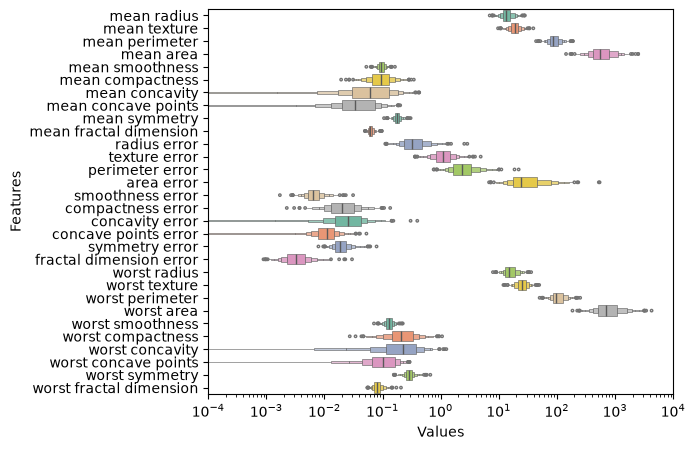

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
ax = sns.boxenplot(
    data=cancer_df,
    orient="h",
    palette="Set2",
    linewidth=0.4,
    flier_kws={"marker": "o", "s": 3},
    line_kws={"linewidth": 1}
)
ax.set(xscale="log", xlim=(1e-4, 1e4), xlabel="Values", ylabel="Features")
plt.show()

In [5]:
import random

random.seed(0)
random_names = random.sample(list(cancer.feature_names), 8)  # type: ignore
cut_df = cancer_df[random_names]

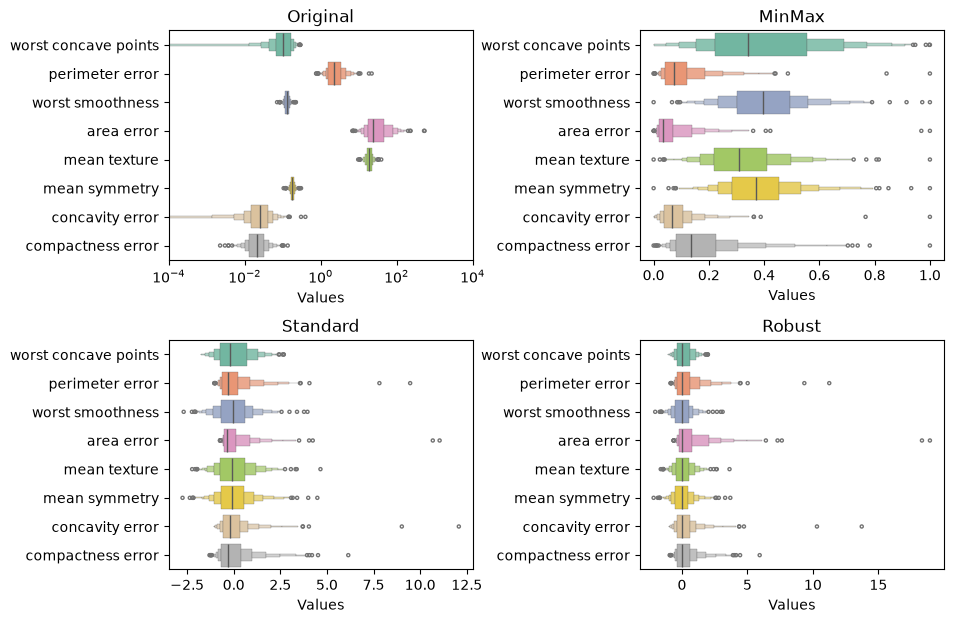

In [7]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler


def plot_norm(df, ax, title):
    sns.boxenplot(
        df,
        orient="h",
        palette="Set2",
        ax=ax,
        linewidth=0.2,
        flier_kws={"marker": "o", "s": 5},
        line_kws={"linewidth": 1},
    )

    ax.set(xlabel="Values", title=title)

fig, axs = plt.subplots(2, 2, figsize=(10, 7))

plot_norm(cut_df, axs[0][0], "Original")
axs[0][0].set(xscale="log", xlim=(1e-4, 1e4))

min_max_x = MinMaxScaler().fit_transform(cut_df)
plot_norm(pd.DataFrame(min_max_x, columns=random_names), axs[0][1], "MinMax")

std_x = StandardScaler().fit_transform(cut_df)
plot_norm(pd.DataFrame(std_x, columns=random_names), axs[1][0], "Standard")

rob_x = RobustScaler().fit_transform(cut_df)
plot_norm(pd.DataFrame(rob_x, columns=random_names), axs[1][1], "Robust")

plt.subplots_adjust(wspace=0.55, hspace=0.35)

plt.show()

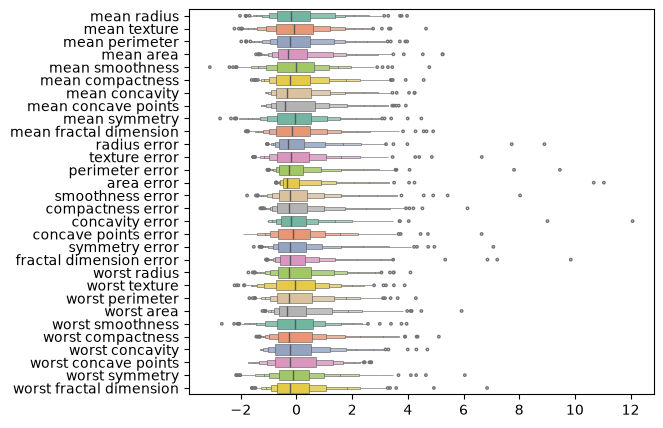

In [8]:
x_norm = StandardScaler().fit_transform(cancer_df)

plt.figure(figsize=(6, 5))
sns.boxenplot(
    data=pd.DataFrame(x_norm, columns=cancer.feature_names),  # type: ignore
    orient="h",
    palette="Set2",
    linewidth=0.4,
    flier_kws={"marker": "o", "s": 3},
    line_kws={"linewidth": 1},
)

ax.set(xlabel="Values")
plt.show()